# Experimental: cross-section going through the South Pole

**This is an experimental example.** It reproduces the Metview gallery example [Cross Section Going Through the South Pole](https://metview.readthedocs.io/en/latest/gen_files/gallery/cross_section_via_pole.html) with earthkit-geo, xarray and earthkit-plots. It shows the ozone mass mixing ratio along the great circle between (65°S, 10°E) and (65°S, 170°W). This great circle passes exactly over the South Pole, because the two points are on opposite meridians (10°E and 170°W) at the same latitude. It uses the new `earthkit.geo.polyline` module, whose interface may still change, to sample a path that crosses a pole. The figure has two panels: a south polar map with the cross-section line (red) above, and the cross-section of ozone below.

This is the simplified version of the [raw notebook](../raw/cross_section_via_pole.ipynb). It uses the `cross_section()` helper from [../xsection.py](../xsection.py) instead of the hand-written regridding and Xarray steps.

The notebook reads a GRIB file. It contains ozone analysis data of 2019-10-15 12 UTC.

To make this notebook work [earthkit-data](https://earthkit-data.readthedocs.io), [earthkit-plots](https://earthkit-plots.readthedocs.io) and xarray have to be installed.

## Imports

In [1]:
import sys
from datetime import datetime

import earthkit.data as ekd
import earthkit.plots as ekp
import numpy as np
from earthkit.geo.polyline import sample_polyline

sys.path.insert(0, "..")  # xsection.py is in docs/experimental
from xsection import cross_section

## Load the data

The file contains the ozone mass mixing ratio `o3` on 20 pressure levels from 1000 to 1 hPa, for a single date and a single step (the analysis time, step 0). It is a GRIB1 file on a regular 1° latitude-longitude grid over the area 65–90°S and all longitudes. Here is a short listing of the first fields.

In [2]:
ds = ekd.from_source("sample", "ozone_pl.grib").to_fieldlist()
print(len(ds), "fields")
ds[:6].ls()

ozone_pl.grib:   0%|          | 0.00/368k [00:00<?, ?B/s]

20 fields


,parameter.variable,time.valid_datetime,time.base_datetime,time.step,vertical.level,vertical.level_type,ensemble.member,geography.grid_type
0,o3,2019-10-15 12:00:00,2019-10-15 12:00:00,0 days,1000,pressure,0,regular_ll
1,o3,2019-10-15 12:00:00,2019-10-15 12:00:00,0 days,850,pressure,0,regular_ll
2,o3,2019-10-15 12:00:00,2019-10-15 12:00:00,0 days,700,pressure,0,regular_ll
3,o3,2019-10-15 12:00:00,2019-10-15 12:00:00,0 days,500,pressure,0,regular_ll
4,o3,2019-10-15 12:00:00,2019-10-15 12:00:00,0 days,400,pressure,0,regular_ll
5,o3,2019-10-15 12:00:00,2019-10-15 12:00:00,0 days,300,pressure,0,regular_ll


## Select the ozone

We select `o3`. The file has 20 pressure levels, and the helper keeps only the 11 levels from 100 to 1 hPa, which are the levels shown by Metview. The values are in kg/kg (the GRIB `units` key is `kg kg**-1`, while earthkit-data reports this ratio as dimensionless), and we keep this unit as Metview does.

In [3]:
o3 = ds.sel({"parameter.variable": "o3"})
o3_levels_hpa = [100, 70, 50, 30, 20, 10, 7, 5, 3, 2, 1]
print(len(o3), "o3 fields on all levels")

20 o3 fields on all levels


## Define the line across the pole

[sample_polyline()](https://earthkit-geo.readthedocs.io) returns the latitudes and longitudes of 201 points along the great circle between (65°S, 10°E) and (65°S, 170°W). The great circle goes straight over the South Pole, so the latitude decreases from -65° to -90° and increases again to -65°. We use an odd number of points, 201, so that the middle point is exactly at the pole. The points are evenly spaced along the line, 0.25° apart. The longitude of the pole point is arbitrary, as all the meridians meet there: the longitude is 10°E before the pole and 170°W after it. The cell below prints these values.

In [4]:
lats, lons = sample_polyline([-65, -65], [10, -170], n=201)
imin = int(np.argmin(lats))
print(lats.shape, (lats[0], lons[0]), (lats[-1], lons[-1]))
print("minimum latitude:", lats.min(), "at point", imin)
print("longitudes before the pole:", np.unique(lons[:imin].round(6)))
print("longitudes after the pole: ", np.unique(lons[imin + 1 :].round(6)))
print("longitude of the pole point:", lons[imin])
assert np.isclose(lats.min(), -90) and imin == 100

(201,) (np.float64(-65.0), np.float64(10.0)) (np.float64(-65.0), np.float64(-170.0))
minimum latitude: -90.0 at point 100
longitudes before the pole: [10.]
longitudes after the pole:  [-170.]
longitude of the pole point: 90.0


## Build the cross-section Dataset with the helper

The `cross_section()` helper from `../xsection.py` does the regridding and builds the Xarray Dataset in one call. The fieldlist is converted to Xarray with `to_xarray()`. The levels given with `levels=` are selected and sorted in ascending order, and the data is regridded onto the 201 points of the line with `earthkit.geo.regrid()`. The helper uses nearest-neighbour interpolation by default. The result is an Xarray Dataset: the ozone `o3` is a variable on `level` (hPa) and `distance` (km). The distance is the cumulative length of the path along the sampled points, the sum of the haversine distances between consecutive points. The latitudes and longitudes of the points are stored as auxiliary coordinates of `distance`. The result follows the CF conventions, and the analysis time is kept as scalar coordinates.

During the regridding earthkit may log an `Error setting gridSpec` message with a traceback, and MIR may print some `GridUnknownError` and `ECCODES` lines (e.g. about an unknown grid or an unstructured grid in a GRIB edition 1 message). They are harmless: the regridding is not affected and the result is correct.

In [5]:
xs = cross_section(o3, lats, lons, levels=o3_levels_hpa)
print("NaNs:", int(xs["o3"].isnull().sum()))
print(f"o3 from {float(xs['o3'].min()):.2e} to {float(xs['o3'].max()):.2e} kg/kg")
xs

Error setting gridSpec={"type": "unstructured_ll", "uid": "2e4be66ba44f082d01163aa91d9249af"}
ECCODES ERROR   :  grib_set_from_grid_spec: 'unstructured_grid' specified but input is GRIB edition 1.
ECCODES ERROR   :  GribFromSpec::set: Invalid argument


Problem with calculation of geographic attributes
Traceback (most recent call last):
  File "/Users/cgr/git/earthkit-data/src/earthkit/data/utils/message.py", line 299, in set
    return eccodes.codes_set(self._handle, name, value)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 2163, in grib_set
    grib_set_string(msgid, key, value)
    ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 523, in grib_set_string
    GRIB_CHECK(lib.grib_set_string(h, key.encode(ENC), bvalue, length_p))
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 232, in GRIB_CHECK
    errors.raise_grib_error(errid)
    ~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/errors.py", line 386, in raise_grib_error

NaNs: 0
o3 from 1.17e-06 to 1.26e-05 kg/kg


<xarray.Dataset> Size: 23kB
Dimensions:                  (level: 11, distance: 201)
Coordinates:
  * level                    (level) int64 88B 1 2 3 5 7 10 20 30 50 70 100
  * distance                 (distance) float64 2kB 0.0 27.8 ... 5.56e+03
    latitude                 (distance) float64 2kB -65.0 -65.25 ... -65.0
    longitude                (distance) float64 2kB 10.0 10.0 ... -170.0 -170.0
    forecast_reference_time  datetime64[ns] 8B 2019-10-15T12:00:00
    step                     timedelta64[ns] 8B 00:00:00
    valid_time               datetime64[ns] 8B ...
Data variables:
    o3                       (level, distance) float64 18kB 3.706e-06 ... 2.0...
Attributes:
    Conventions:  CF-1.8
    institution:  ECMWF

## The tick labels of the cross-section

Metview puts 9 ticks on the horizontal axis, at the angular distances 1°, 7°, 13°, …, 49° from the start of the line, and labels them with the latitude and the longitude. Beyond the pole it continues the latitude past -90°, so its labels are "66°S/10°E", "72°S/10°E", "78°S/10°E", "84°S/10°E", "90°S/10°E", "96°S/10°E", "102°S/10°E", "108°S/10°E" and "114°S/10°E". Those latitudes do not exist. Here we use the real coordinates of the same 9 points, i.e. "66°S/10°E", "72°S/10°E", "78°S/10°E", "84°S/10°E", "90°S", "84°S/170°W", "78°S/170°W", "72°S/170°W" and "66°S/170°W": the "96°S/10°E" of Metview is "84°S/170°W", "102°S/10°E" is "78°S/170°W", "108°S/10°E" is "72°S/170°W" and "114°S/10°E" is "66°S/170°W". The ticks are at the same positions as in Metview. The labels are computed from the sampled points, taking the point which is the nearest to the distance of each tick. The distance of an angle is the angle in radians times the Earth radius, 6371.229 km.

In [6]:
EARTH_RADIUS_KM = 6371.229  # radius used by earthkit.geo

distance = xs["distance"].values

tick_angles = np.arange(1, 50, 6)  # 1, 7, 13, ..., 49 degrees from the start
tick_distance = np.deg2rad(tick_angles) * EARTH_RADIUS_KM
tick_index = [int(np.argmin(np.abs(distance - d))) for d in tick_distance]


def label(lat, lon):
    if lat <= -90 + 1e-6:
        return "90°S"  # the pole itself, all the longitudes are the same point
    return f"{abs(lat):.0f}°S/{abs(lon):.0f}°{'E' if lon >= 0 else 'W'}"


tick_labels = [label(lats[i], lons[i]) for i in tick_index]
tick_distance = distance[tick_index]
print(tick_labels)

['66°S/10°E', '72°S/10°E', '78°S/10°E', '84°S/10°E', '90°S', '84°S/170°W', '78°S/170°W', '72°S/170°W', '66°S/170°W']


## Plot the map and the cross-section in one figure

We use one earthkit-plots `Figure` with two rows: a map in the first row and an ordinary (non-map) subplot in the second row, which is taller. The panels are added with `add_map()` and `add_subplot()`.

**Map.** It is a south polar stereographic map down to about 50°S. The central longitude is 20°W, so that meridian 160°E points down, as Metview's `map_vertical_longitude=160` does. The Antarctic Peninsula is then at the top-left, and the line goes from 10°E at the top-right, across the pole, to 170°W at the bottom-left, as in Metview. The gridlines have no labels, as in Metview (`map_label="off"`). The land is grey, the coastlines are thick, and the meridians are drawn every 30° with the parallels every 10°. The cross-section line is red. The sampled points of the great circle are plotted as a line: it goes through the pole. The extent of the map is a square centred on the pole, which reaches 50°S in the middle of each side. It is set with `set_extent()` on the axis `.ax` in projected coordinates, because a longitude-latitude domain does not give a centred extent on a polar projection.

**Cross-section.** The filled contours of ozone use the levels from 0 to 1.5e-5 kg/kg every 1.5e-6, with the matplotlib colormap `GnBu`, which goes from very light to dark blue, close to the Metview palette `m_blue_green2_10`. Dark grey contour lines with labels are drawn at the same levels. The colour bar is added with the `legend()` method of the figure (the contour lines have no colour bar of their own, `legend_style=None`), and the numbers of the colour bar and of the contour lines are in scientific notation. The vertical axis is the logarithmic pressure, with 100 hPa at the bottom and 1 hPa at the top. The horizontal axis has the 9 ticks of the previous section.

Two details need explanation:

- `resample=False` is needed for `contourf()` and `contour()` of the cross-section. By default earthkit-plots resamples the data onto a 1000 × 1000 latitude-longitude grid, which is wrong for a distance-pressure section.
- The logarithmic axis, the axis limits, the ticks and the labels are set with matplotlib calls on the axis `.ax` of the subplot, because earthkit-plots has no dedicated option for them.

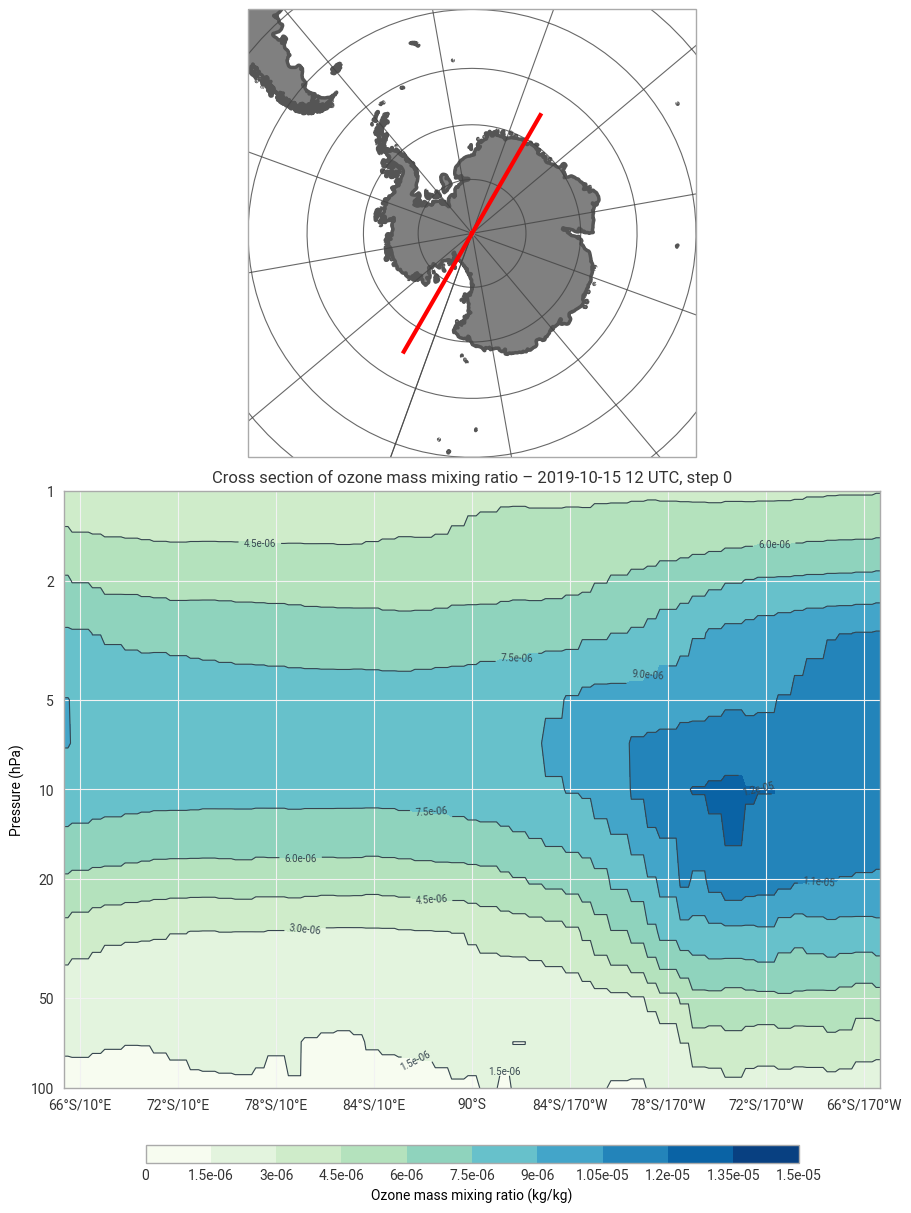

In [7]:
import cartopy.crs as ccrs  # south polar stereographic projection for the map

base_date = datetime(2019, 10, 15, 12)
o3_levels = list(np.linspace(0, 1.5e-5, 11))

fig = ekp.Figure(rows=2, columns=1, figsize=(9, 12), height_ratios=[3, 4])

# --- map: the cross-section line over the South Pole ---
m = fig.add_map(crs=ccrs.SouthPolarStereo(central_longitude=-20))
# square extent, centred on the pole, which reaches 50°S at the middle of each side
x50, y50 = m.crs.transform_point(0, -50, ccrs.PlateCarree())
radius = float(np.hypot(x50, y50))
m.ax.set_extent([-radius, radius, -radius, radius], crs=m.crs)
m.land(color="grey")
m.coastlines(linewidth=2.5)
m.gridlines(xstep=30, ystep=10, color="#434343", linewidth=0.8, draw_labels=False)
m.line(x=lons, y=lats, color="red", linewidth=3)

# --- cross-section: ozone mass mixing ratio ---
c = fig.add_subplot()
c.contourf(
    xs["o3"],
    x="distance",
    y="level",
    style=ekp.styles.Style(
        levels=o3_levels,
        colors="GnBu",
        legend_kwargs={"format": "%.1e"},
    ),
    resample=False,
)
c.contour(
    xs["o3"],
    x="distance",
    y="level",
    style=ekp.styles.Contour(
        levels=o3_levels,
        colors="#36454f",
        linewidths=0.8,
        labels=True,
        label_kwargs={"label_fmt": "%.1e"},
        legend_style=None,  # no second colour bar for the lines
    ),
    resample=False,
)
fig.legend(subplots=[c], label="Ozone mass mixing ratio (kg/kg)")

ax = c.ax
ax.set_yscale("log")
ax.set_ylim(100, 1)  # 100 hPa at the bottom, 1 hPa at the top
pressure_ticks = [1, 2, 5, 10, 20, 50, 100]
ax.set_yticks(pressure_ticks)
ax.set_yticklabels([str(p) for p in pressure_ticks])
ax.minorticks_off()
ax.set_xlim(distance[0], distance[-1])
ax.set_xticks(tick_distance)
ax.set_xticklabels(tick_labels)
ax.set_ylabel("Pressure (hPa)")
ax.set_title(f"Cross section of ozone mass mixing ratio – {base_date:%Y-%m-%d %H} UTC, step 0")

fig.show()